In [1]:
import os
print('Working directory:', os.getcwd())

Working directory: E:\.MSc\Research2\Research\Data_Prep_ipynb


# 🏗️ HeartCycle — Notebook 3: Build Final ML-Ready Dataset

---

## Purpose
This notebook is **Step 3** — assembling the final ML-ready dataset from the preprocessed `.npz` files created in Notebook 2.

We:
1. Aggregate all `.npz` files by **subject-level split** (train/val/test) — no data leakage
2. Filter out invalid/artifact beats
3. Extract **hand-crafted features** for traditional ML baselines (RQ2)
4. Inspect the final array shapes, label distributions, and per-split statistics
5. Save everything as clean `.npy` files ready for any framework

## The Split Strategy
```
Train      : CHC01–CHC12  (12 subjects, ~70%)
Validation : CHC13–CHC15  ( 3 subjects, ~18%)
Test       : CHC16–CHC17  ( 2 subjects, ~12%)  ← NEVER TOUCH UNTIL FINAL EVAL
```
> ⚠️ **Critical**: Subject-level split prevents data leakage. Each subject's ICG morphology is unique — mixing subjects across splits would inflate metrics artificially.

---
**Requires:** `.npz` files in `./output/preprocessed/` from Notebook 2.

In [2]:
PREPROCESSED_DIR  = './output/preprocessed'
FINAL_DATASET_DIR = './output/final_dataset'

import os
for d in [FINAL_DATASET_DIR, f'{FINAL_DATASET_DIR}/train',
          f'{FINAL_DATASET_DIR}/val', f'{FINAL_DATASET_DIR}/test']:
    os.makedirs(d, exist_ok=True)
print('Directories ready.')

Directories ready.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import skew, kurtosis
import json, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

SUBJECT_SPLIT = {
    'train': [f'CHC{i:02d}' for i in range(1, 13)],    # CHC01-CHC12
    'val':   ['CHC14'],
    'test':  ['CHC16', 'CHC17'],
}

FS       = 200
WIN_LEN  = 200
PRE_R_MS = 200
R_IDX    = int(PRE_R_MS * FS / 1000)  # 40

prep_dir = Path(PREPROCESSED_DIR)
npz_files = sorted(prep_dir.glob('*.npz'))
print(f'Found {len(npz_files)} .npz files')
print(f'\nSubject split:')
for split, subjs in SUBJECT_SPLIT.items():
    print(f'  {split:12s}: {subjs}')

Found 212 .npz files

Subject split:
  train       : ['CHC01', 'CHC02', 'CHC03', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC11', 'CHC12']
  val         : ['CHC14']
  test        : ['CHC16', 'CHC17']


## 1. Load and Inspect All Preprocessed Records

In [4]:
# Load all .npz files into memory
import re

all_data = {}
record_stats = []

for f in npz_files:
    stem = f.stem
    subject_raw = stem.split('_')[0]
    record_id  = '_'.join(stem.split('_')[1:])
    
    # Normalize subject id to match SUBJECT_SPLIT keys (e.g. CH17 -> CHC17 or CH01 -> CHC01)
    m = re.search(r'(\d+)', subject_raw)
    if m:
        subject_id = f'CHC{int(m.group(1)):02d}'
    else:
        subject_id = subject_raw
    
    # Determine split
    split = None
    for s, subjs in SUBJECT_SPLIT.items():
        if subject_id in subjs:
            split = s; break
    if split is None:
        print(f'  ⚠️ {subject_raw} -> {subject_id} not in any split — skipping')
        continue
    
    try:
        data = np.load(f, allow_pickle=True)
        n = len(data['icg_windows'])
        labels = data['labels']
        biases = data['biases']
        
        valid = labels[(labels[:,0] > 0) & (labels[:,1] > 0)]
        valid_b = biases[:,0][~np.isnan(biases[:,0])]
        valid_x = biases[:,1][~np.isnan(biases[:,1])]
        
        record_stats.append({
            'subject_id': subject_id, 'record_id': record_id,
            'split': split, 'n_beats': n,
            'n_valid_labels': len(valid),
            'mean_pep_ms':  float(valid[:,0].mean()) if len(valid) else np.nan,
            'mean_lvet_ms': float(valid[:,1].mean()) if len(valid) else np.nan,
            'mean_b_bias':  float(valid_b.mean()) if len(valid_b) else np.nan,
            'mean_x_bias':  float(valid_x.mean()) if len(valid_x) else np.nan,
        })
        
        if subject_id not in all_data:
            all_data[subject_id] = {'split': split, 'records': []}
        all_data[subject_id]['records'].append({
            'record_id': record_id,
            'icg_windows':    data['icg_windows'],
            'ecg_windows':    data['ecg_windows'],
            'multimodal':     data['multimodal'],
            'labels':         data['labels'],
            'biases':         data['biases'],
            'cp_indices':     data['cp_indices'],
        })
    except Exception as e:
        print(f'  Error loading {f.name}: {e}')

stats_df = pd.DataFrame(record_stats)
print(f'\nLoaded {len(stats_df)} records from {len(all_data)} subjects')
print(f'\nRecords per split:')
if 'split' in stats_df.columns and len(stats_df):
    print(stats_df.groupby('split')[['n_beats', 'n_valid_labels']].sum())
else:
    print('  No records to summarize.')

  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — skipping
  ⚠️ CHC13 -> CHC13 not in any split — s

  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping
  ⚠️ CHC15 -> CHC15 not in any split — skipping



Loaded 172 records from 15 subjects

Records per split:
       n_beats  n_valid_labels
split                         
test       173              69
train     1013             283
val        114              44


In [5]:
# Why are CHC03 / CHC11 absent from the final loaded set? (train split = CHC01–CHC12)
# They ARE loaded into all_data, but every label-valid beat fails quality_filter's
# physiological gate: 50 <= PEP <= 250 ms and 150 <= LVET <= 500 ms (see quality-filter-cell).
# This differs from CHC13/CHC15, which had zero label-matched beats ("missing label").
for subj in ['CHC03', 'CHC11']:
    if subj not in all_data:
        print(f'{subj}: not present in all_data at all'); continue
    lbl = np.concatenate([r['labels'] for r in all_data[subj]['records']])
    has_label = (lbl[:, 0] > 0) & (lbl[:, 1] > 0) & ~np.isnan(lbl[:, 0]) & ~np.isnan(lbl[:, 1])
    v = lbl[has_label]
    pass_pep  = (v[:, 0] >= 50) & (v[:, 0] <= 250)
    pass_both = pass_pep & (v[:, 1] >= 150) & (v[:, 1] <= 500)
    print(f'{subj}: {len(lbl)} beats total | {has_label.sum()} with PEP&LVET labels | '
          f'{pass_pep.sum()} pass PEP range | {pass_both.sum()} retained after PEP+LVET range')
    print(f'   GT PEP (ms), label-valid beats: {np.round(np.sort(v[:, 0]), 1).tolist()}')
    print(f'   GT LVET (ms) range: [{v[:, 1].min():.1f}, {v[:, 1].max():.1f}]')
    print(f'   -> all GT PEP below the 50 ms physiological floor: {bool((v[:, 0] < 50).all())}')

CHC03: 89 beats total | 9 with PEP&LVET labels | 0 pass PEP range | 0 retained after PEP+LVET range
   GT PEP (ms), label-valid beats: [22.100000381469727, 25.700000762939453, 25.700000762939453, 25.700000762939453, 25.700000762939453, 33.099998474121094, 36.79999923706055, 40.400001525878906, 44.099998474121094]
   GT LVET (ms) range: [256.1, 266.2]
   -> all GT PEP below the 50 ms physiological floor: True
CHC11: 48 beats total | 16 with PEP&LVET labels | 0 pass PEP range | 0 retained after PEP+LVET range
   GT PEP (ms), label-valid beats: [28.600000381469727, 29.0, 29.100000381469727, 30.200000762939453, 30.700000762939453, 31.600000381469727, 32.0, 32.5, 33.900001525878906, 34.5, 34.599998474121094, 34.599998474121094, 37.79999923706055, 39.20000076293945, 39.5, 40.400001525878906]
   GT LVET (ms) range: [233.5, 273.5]
   -> all GT PEP below the 50 ms physiological floor: True


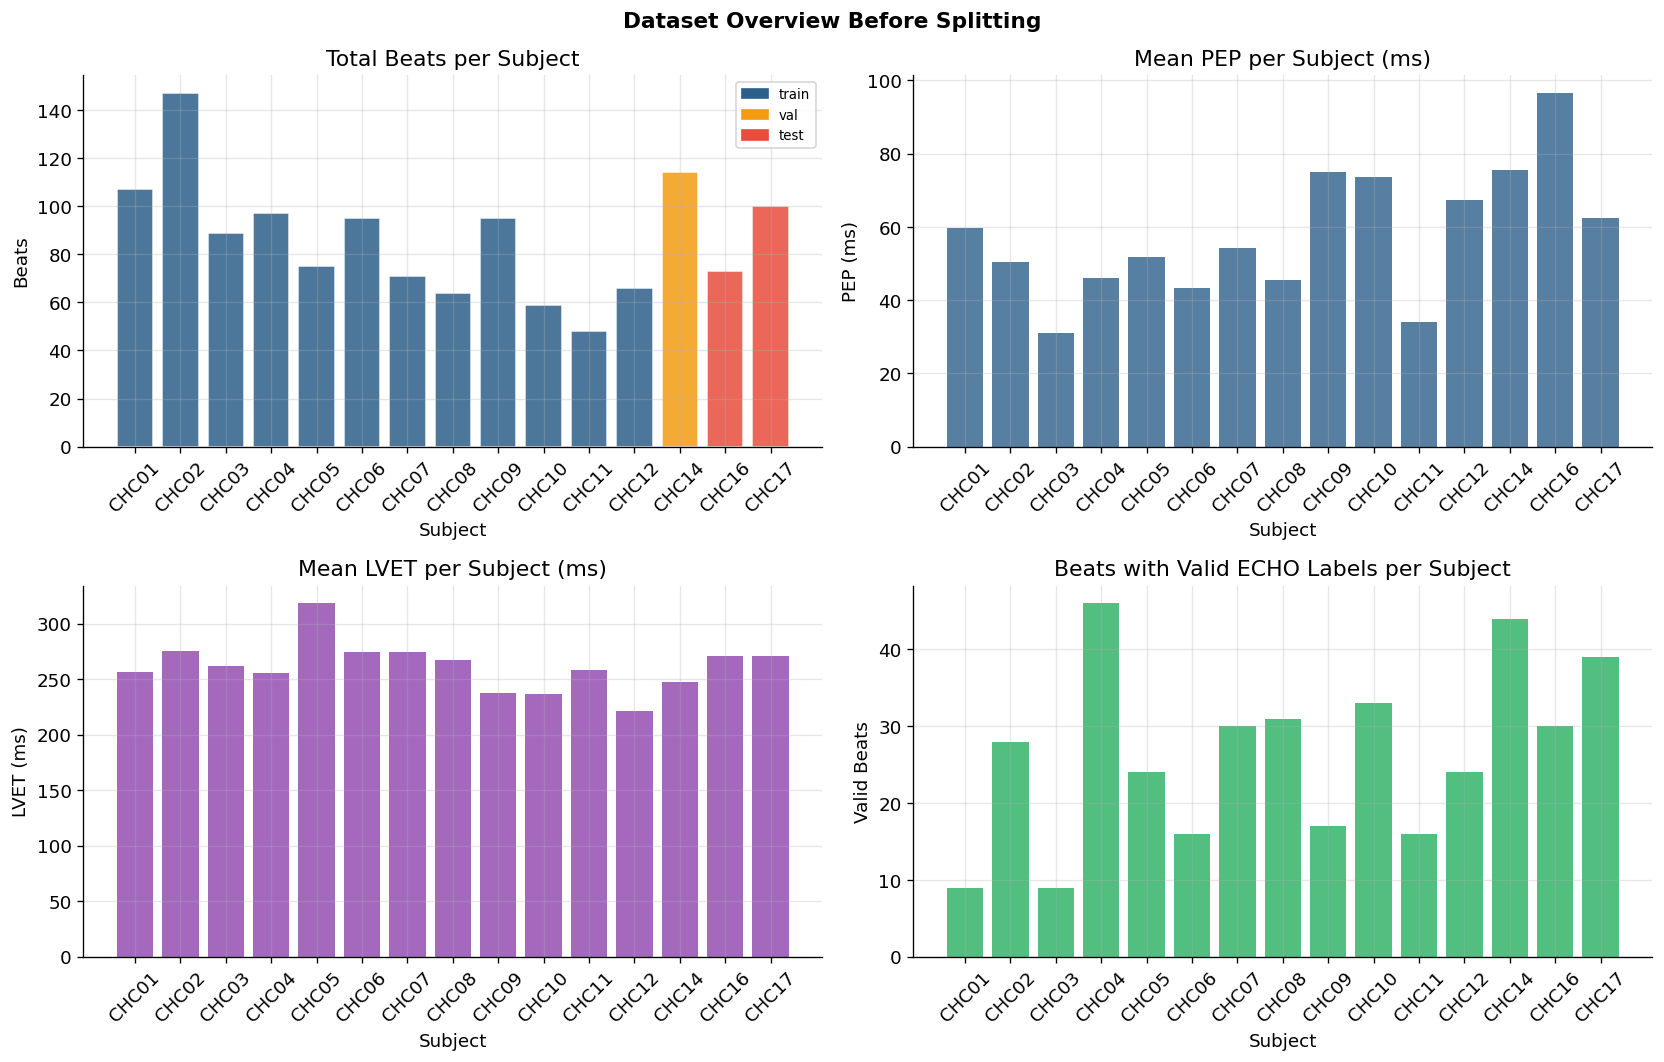

In [6]:
# Overview of what we have
import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Dataset Overview Before Splitting', fontsize=13, fontweight='bold')

split_palette = {'train': '#2C5F8A', 'val': '#F39C12', 'test': '#E74C3C'}

# Beats per subject
beats_by_subj = stats_df.groupby(['subject_id', 'split'])['n_beats'].sum().reset_index()
colors = [split_palette.get(s, 'gray') for s in beats_by_subj['split']]
axes[0,0].bar(beats_by_subj['subject_id'], beats_by_subj['n_beats'], color=colors, alpha=0.85, edgecolor='white')
axes[0,0].set_title('Total Beats per Subject')
axes[0,0].set_xlabel('Subject')
axes[0,0].set_ylabel('Beats')
axes[0,0].tick_params(axis='x', rotation=45)
patches = [mpatches.Patch(color=c, label=s) for s, c in split_palette.items()]
axes[0,0].legend(handles=patches, fontsize=8)
# Mean PEP per subject
pep_by_subj = stats_df.dropna(subset=['mean_pep_ms']).groupby('subject_id')['mean_pep_ms'].mean()
axes[0,1].bar(pep_by_subj.index, pep_by_subj.values, color='#2C5F8A', alpha=0.8)
axes[0,1].set_title('Mean PEP per Subject (ms)')
axes[0,1].set_xlabel('Subject')
axes[0,1].set_ylabel('PEP (ms)')
axes[0,1].tick_params(axis='x', rotation=45)

# Mean LVET per subject
lvet_by_subj = stats_df.dropna(subset=['mean_lvet_ms']).groupby('subject_id')['mean_lvet_ms'].mean()
axes[1,0].bar(lvet_by_subj.index, lvet_by_subj.values, color='#8E44AD', alpha=0.8)
axes[1,0].set_title('Mean LVET per Subject (ms)')
axes[1,0].set_xlabel('Subject')
axes[1,0].set_ylabel('LVET (ms)')
axes[1,0].tick_params(axis='x', rotation=45)

# Valid labels per subject
valid_by_subj = stats_df.groupby('subject_id')['n_valid_labels'].sum()
axes[1,1].bar(valid_by_subj.index, valid_by_subj.values, color='#27AE60', alpha=0.8)
axes[1,1].set_title('Beats with Valid ECHO Labels per Subject')
axes[1,1].set_xlabel('Subject')
axes[1,1].set_ylabel('Valid Beats')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 2. Quality Filtering

In [7]:
def quality_filter(icg_wins, ecg_wins, labels):
    """
    Remove beats that are:
    - Missing ground truth labels
    - Physiologically impossible PEP/LVET
    - Flat-line signals
    """
    n = len(icg_wins)
    mask = np.ones(n, dtype=bool)
    reasons = np.zeros(n, dtype=int)  # 0=valid, 1=missing label, 2=physio, 3=flatline
    
    for i in range(n):
        pep, lvet = labels[i, 0], labels[i, 1]
        if pep <= 0 or lvet <= 0 or np.isnan(pep) or np.isnan(lvet):
            mask[i] = False; reasons[i] = 1; continue
        if not (50 <= pep <= 250):
            mask[i] = False; reasons[i] = 2; continue
        if not (150 <= lvet <= 500):
            mask[i] = False; reasons[i] = 2; continue
        if np.std(icg_wins[i]) < 0.01 or np.std(ecg_wins[i]) < 0.01:
            mask[i] = False; reasons[i] = 3; continue
    
    return mask, reasons

# Test on first subject
first_subj = list(all_data.keys())[0]
first_recs  = all_data[first_subj]['records']

all_icg_s = np.concatenate([r['icg_windows'] for r in first_recs])
all_ecg_s = np.concatenate([r['ecg_windows'] for r in first_recs])
all_lbl_s = np.concatenate([r['labels'] for r in first_recs])

mask, reasons = quality_filter(all_icg_s, all_ecg_s, all_lbl_s)
n_total = len(mask)
n_valid = mask.sum()
print(f'Subject {first_subj}: {n_valid}/{n_total} beats pass quality filter ({100*n_valid/n_total:.1f}%)')
print(f'  Removed — missing labels:        {(reasons==1).sum()}')
print(f'  Removed — physiological range:   {(reasons==2).sum()}')
print(f'  Removed — flat-line signal:      {(reasons==3).sum()}')

Subject CHC01: 9/107 beats pass quality filter (8.4%)
  Removed — missing labels:        98
  Removed — physiological range:   0
  Removed — flat-line signal:      0


## 3. Hand-Crafted Features for Traditional ML (RQ2)
For RQ2, we need a feature matrix `X_features` to train Random Forest, SVR, XGBoost etc.
These features encode domain knowledge about ICG morphology.

In [8]:
def extract_features(icg_win, ecg_win, fs=200):
    """
    Extract 30 domain-specific features from one beat window (an earlier
    design called for 35; several were dropped and this docstring was never
    updated — the actual, saved feature count is 30, confirmed by the printed
    'Feature vector length' below and dataset_stats.json's n_features field).
    Groups: A) ICG B-region  B) ICG X-region  C) ICG global  D) ECG  E) Cross-signal
    """
    r_idx  = int(0.2 * fs)  # 40 samples (200ms pre-window)
    feats  = []
    names  = []
    
    def add(val, name):
        feats.append(float(val) if not (np.isnan(val) or np.isinf(val)) else 0.0)
        names.append(name)
    
    # ─── A. ICG B-region (50–200ms after R) ───
    blo = r_idx + int(0.05*fs); bhi = r_idx + int(0.20*fs)
    blo, bhi = max(0, blo), min(len(icg_win), bhi)
    seg = icg_win[blo:bhi] if bhi > blo else np.array([0.0])
    add(seg.min(),  'b_min');     add(seg.max(), 'b_max')
    add(seg.mean(), 'b_mean');    add(seg.std(), 'b_std')
    add(np.argmin(seg)/fs*1000, 'b_t_min_ms')
    add(np.argmax(seg)/fs*1000, 'b_t_max_ms')
    add(np.trapz(seg)/fs, 'b_area')
    
    # ─── B. ICG X-region (200–500ms after R) ───
    xlo = r_idx + int(0.20*fs); xhi = r_idx + int(0.50*fs)
    xlo, xhi = max(0, xlo), min(len(icg_win), xhi)
    xseg = icg_win[xlo:xhi] if xhi > xlo else np.array([0.0])
    add(xseg.min(),  'x_min');    add(xseg.max(), 'x_max')
    add(xseg.mean(), 'x_mean');   add(xseg.std(), 'x_std')
    add(np.argmin(xseg)/fs*1000, 'x_t_min_ms')
    add(np.trapz(xseg)/fs, 'x_area')
    
    # ─── C. ICG systolic phase (R to X) ───
    sys_seg = icg_win[r_idx:xhi] if xhi > r_idx else np.array([0.0])
    add(sys_seg.max(), 'sys_peak')
    add(np.argmax(sys_seg)/fs*1000, 'sys_t_peak_ms')
    add(np.trapz(sys_seg)/fs, 'sys_area')
    add((sys_seg > 0).sum()/fs*1000, 'sys_pos_dur_ms')
    
    # ─── C2. ICG global stats ───
    add(icg_win.mean(), 'icg_mean');  add(icg_win.std(), 'icg_std')
    add(float(skew(icg_win)), 'icg_skew');  add(float(kurtosis(icg_win)), 'icg_kurt')
    add(icg_win.max() - icg_win.min(), 'icg_p2p')
    add(np.argmax(icg_win)/fs*1000, 'icg_t_peak_ms')
    
    # ─── D. ECG features ───
    rlo = max(0, r_idx-5); rhi = min(len(ecg_win), r_idx+5)
    add(ecg_win[rlo:rhi].max(), 'r_amp')
    add(ecg_win.std(), 'ecg_std')
    tlo = r_idx + int(0.30*fs); thi = r_idx + int(0.50*fs)
    tlo, thi = max(0,tlo), min(len(ecg_win),thi)
    tseg = ecg_win[tlo:thi] if thi > tlo else np.array([0.0])
    add(tseg.max(), 't_amp')
    add(np.argmax(tseg)/fs*1000, 't_t_peak_ms')
    stlo = r_idx + int(0.06*fs); sthi = r_idx + int(0.14*fs)
    stlo, sthi = max(0,stlo), min(len(ecg_win),sthi)
    add(ecg_win[stlo:sthi].mean() if sthi > stlo else 0, 'st_mean')
    
    # ─── E. Cross-signal features ───
    sys_len = min(len(sys_seg), len(ecg_win) - r_idx)
    if sys_len > 5:
        corr = np.corrcoef(sys_seg[:sys_len], ecg_win[r_idx:r_idx+sys_len])[0,1]
        add(corr if not np.isnan(corr) else 0, 'icg_ecg_corr')
    else:
        add(0, 'icg_ecg_corr')
    icg_peak_i = np.argmax(icg_win[r_idx:]) + r_idx
    add((icg_peak_i - r_idx)/fs*1000, 'ecg_icg_phase_ms')
    
    return np.array(feats, dtype=np.float32), names

# Test
from pathlib import Path
test_npz = np.load(list(prep_dir.glob('*.npz'))[0])
feat, names = extract_features(test_npz['icg_windows'][0], test_npz['ecg_windows'][0])
print(f'Feature vector length: {len(feat)}')
print(f'\nAll features:')
for i, (n_, v) in enumerate(zip(names, feat)):
    print(f'  [{i:2d}] {n_:22s}: {v:.4f}')

Feature vector length: 30

All features:
  [ 0] b_min                 : -0.1118
  [ 1] b_max                 : 3.1493
  [ 2] b_mean                : 1.5075
  [ 3] b_std                 : 1.1303
  [ 4] b_t_min_ms            : 25.0000
  [ 5] b_t_max_ms            : 80.0000
  [ 6] b_area                : 0.2236
  [ 7] x_min                 : -2.2798
  [ 8] x_max                 : 0.9940
  [ 9] x_mean                : -0.4368
  [10] x_std                 : 0.7500
  [11] x_t_min_ms            : 135.0000
  [12] x_area                : -0.1328
  [13] sys_peak              : 3.1493
  [14] sys_t_peak_ms         : 130.0000
  [15] sys_area              : 0.0911
  [16] sys_pos_dur_ms        : 270.0000
  [17] icg_mean              : 0.0000
  [18] icg_std               : 1.0000
  [19] icg_skew              : 0.9564
  [20] icg_kurt              : 1.6599
  [21] icg_p2p               : 5.4291
  [22] icg_t_peak_ms         : 330.0000
  [23] r_amp                 : 2.7767
  [24] ecg_std               : 1.

## 4. Build and Save Train/Val/Test Splits

In [9]:
split_summaries = {}

for split_name, subjects in SUBJECT_SPLIT.items():
    print(f"\n{'='*50}")
    print(f'Building {split_name.upper()} split: {subjects}')
    
    # Collect all records for these subjects
    split_icg, split_ecg, split_labels = [], [], []
    split_biases, split_cp = [], []
    split_meta = []
    
    for subj in subjects:
        if subj not in all_data:
            print(f'  ⚠️ {subj}: no data found')
            continue
        for rec in all_data[subj]['records']:
            split_icg.append(rec['icg_windows'])
            split_ecg.append(rec['ecg_windows'])
            split_labels.append(rec['labels'])
            split_biases.append(rec['biases'])
            split_cp.append(rec['cp_indices'])
            for j in range(len(rec['icg_windows'])):
                split_meta.append({'subject_id': subj, 'record_id': rec['record_id'], 'beat_idx': j})
    
    if not split_icg:
        print(f'  No data for this split')
        continue
    
    icg_all = np.concatenate(split_icg,    axis=0)
    ecg_all = np.concatenate(split_ecg,    axis=0)
    lbl_all = np.concatenate(split_labels, axis=0)
    bias_all = np.concatenate(split_biases,axis=0)
    cp_all  = np.concatenate(split_cp,     axis=0)
    meta_df = pd.DataFrame(split_meta)
    n_raw   = len(icg_all)
    
    print(f'  Raw beats: {n_raw}')
    
    # Quality filter
    mask, reasons = quality_filter(icg_all, ecg_all, lbl_all)
    print(f'  Missing label: {(reasons==1).sum()}  Physio range: {(reasons==2).sum()}  Flat-line: {(reasons==3).sum()}')
    icg_f  = icg_all[mask];  ecg_f   = ecg_all[mask]
    lbl_f  = lbl_all[mask];  bias_f  = bias_all[mask]
    cp_f   = cp_all[mask];   meta_f  = meta_df[mask].reset_index(drop=True)
    n_valid = mask.sum()
    print(f'  After filter: {n_valid} beats ({100*n_valid/n_raw:.1f}% retained)')
    
    # Multimodal array (N, 2, 200)
    multi_f = np.stack([icg_f, ecg_f], axis=1)
    
    # Hand-crafted features (N, F)
    print(f'  Extracting features...')
    feat_list = []
    feat_names = None
    for i in range(len(icg_f)):
        fv, fn = extract_features(icg_f[i], ecg_f[i])
        feat_list.append(fv)
        if feat_names is None: feat_names = fn
    X_feat = np.stack(feat_list)
    
    # Labels
    y_pep  = lbl_f[:, 0]
    y_lvet = lbl_f[:, 1]
    y_avo  = lbl_f[:, 2]
    y_avc  = lbl_f[:, 3]
    
    # Save
    out = Path(FINAL_DATASET_DIR) / split_name
    np.save(out / 'X_icg.npy',       icg_f.astype(np.float32))
    np.save(out / 'X_ecg.npy',       ecg_f.astype(np.float32))
    np.save(out / 'X_multi.npy',     multi_f.astype(np.float32))
    np.save(out / 'X_features.npy',  X_feat.astype(np.float32))
    np.save(out / 'y_pep.npy',       y_pep.astype(np.float32))
    np.save(out / 'y_lvet.npy',      y_lvet.astype(np.float32))
    np.save(out / 'y_avo.npy',       y_avo.astype(np.float32))
    np.save(out / 'y_avc.npy',       y_avc.astype(np.float32))
    np.save(out / 'biases.npy',      bias_f.astype(np.float32))
    np.save(out / 'cp_indices.npy',  cp_f.astype(np.int32))
    meta_f.to_csv(out / 'meta.csv', index=False)
    if feat_names:
        with open(out / 'feature_names.json', 'w') as fp:
            json.dump(feat_names, fp, indent=2)
    
    split_summaries[split_name] = {
        'subjects': subjects, 'n_raw': int(n_raw), 'n_valid': int(n_valid),
        'pep_mean': float(y_pep.mean()), 'pep_std': float(y_pep.std()),
        'lvet_mean': float(y_lvet.mean()), 'lvet_std': float(y_lvet.std()),
        'n_features': int(X_feat.shape[1]), 'win_len': 200,
    }
    print(f'  PEP:  {y_pep.mean():.1f} ± {y_pep.std():.1f} ms')
    print(f'  LVET: {y_lvet.mean():.1f} ± {y_lvet.std():.1f} ms')
    print(f'  ✅ Saved to {out}/')

with open(f'{FINAL_DATASET_DIR}/dataset_stats.json', 'w') as fp:
    json.dump(split_summaries, fp, indent=2)
with open(f'{FINAL_DATASET_DIR}/subject_split.json', 'w') as fp:
    json.dump(SUBJECT_SPLIT, fp, indent=2)
print(f'\n✅ All splits saved!')


Building TRAIN split: ['CHC01', 'CHC02', 'CHC03', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC11', 'CHC12']
  Raw beats: 1013
  Missing label: 730  Physio range: 117  Flat-line: 0
  After filter: 166 beats (16.4% retained)
  Extracting features...


  PEP:  63.7 ± 10.8 ms
  LVET: 254.8 ± 31.9 ms
  ✅ Saved to output\final_dataset\train/

Building VAL split: ['CHC14']
  Raw beats: 114
  Missing label: 70  Physio range: 0  Flat-line: 0
  After filter: 44 beats (38.6% retained)
  Extracting features...
  PEP:  75.5 ± 7.3 ms
  LVET: 248.1 ± 12.1 ms
  ✅ Saved to output\final_dataset\val/

Building TEST split: ['CHC16', 'CHC17']
  Raw beats: 173
  Missing label: 104  Physio range: 0  Flat-line: 0
  After filter: 69 beats (39.9% retained)
  Extracting features...
  PEP:  77.1 ± 18.1 ms
  LVET: 271.5 ± 11.5 ms
  ✅ Saved to output\final_dataset\test/

✅ All splits saved!


In [10]:
all_labels = []
for subject_data in all_data.values():
    all_labels.extend(rec['labels'] for rec in subject_data['records'])
lbl_all_full = np.concatenate(all_labels, axis=0)

v = ~np.isnan(lbl_all_full[:, 2]) & ~np.isnan(lbl_all_full[:, 3])
frac_equal = np.mean(np.isclose(lbl_all_full[v, 2], lbl_all_full[v, 3]))
print(f'Fraction of beats with AVO ≈ AVC: {frac_equal:.1%}  (n={v.sum()})')

Fraction of beats with AVO ≈ AVC: 0.0%  (n=420)


## 5. Verify and Inspect Final Arrays

In [11]:
# Load back and verify
def load_split(data_dir, split):
    d = Path(data_dir) / split
    return {
        'X_icg':    np.load(d / 'X_icg.npy'),
        'X_ecg':    np.load(d / 'X_ecg.npy'),
        'X_multi':  np.load(d / 'X_multi.npy'),
        'X_feat':   np.load(d / 'X_features.npy'),
        'y_pep':    np.load(d / 'y_pep.npy'),
        'y_lvet':   np.load(d / 'y_lvet.npy'),
        'biases':   np.load(d / 'biases.npy'),
        'cp_idx':   np.load(d / 'cp_indices.npy'),
    }

print('=== FINAL DATASET SHAPE VERIFICATION ===')
for split in ['train', 'val', 'test']:
    try:
        ds = load_split(FINAL_DATASET_DIR, split)
        N = len(ds['X_icg'])
        print(f'\n{split.upper()} ({N:,} beats):')
        print(f'  X_icg:     {ds["X_icg"].shape}   ← ICG-only input')
        print(f'  X_ecg:     {ds["X_ecg"].shape}   ← ECG-only input')
        print(f'  X_multi:   {ds["X_multi"].shape}  ← Multimodal (ICG+ECG)')
        print(f'  X_feat:    {ds["X_feat"].shape}   ← Hand-crafted features')
        print(f'  y_pep:     {ds["y_pep"].shape}   ← PEP target (ms)')
        print(f'  y_lvet:    {ds["y_lvet"].shape}   ← LVET target (ms)')
        print(f'  biases:    {ds["biases"].shape}   ← [B_bias, X_bias, PEP_bias, LVET_bias]')
        print(f'  cp_idx:    {ds["cp_idx"].shape}   ← [R_idx, B_idx, X_idx] in window')
        print(f'  PEP:  {ds["y_pep"].mean():.1f} ± {ds["y_pep"].std():.1f} ms')
        print(f'  LVET: {ds["y_lvet"].mean():.1f} ± {ds["y_lvet"].std():.1f} ms')
        # Verify normalization
        print(f'  ICG normalized: mean={ds["X_icg"].mean():.3f}, std={ds["X_icg"].std():.3f} (expect ~0, ~1)')
    except FileNotFoundError:
        print(f'  {split}: files not found (check preprocessing completed)')

=== FINAL DATASET SHAPE VERIFICATION ===



TRAIN (166 beats):
  X_icg:     (166, 200)   ← ICG-only input
  X_ecg:     (166, 200)   ← ECG-only input
  X_multi:   (166, 2, 200)  ← Multimodal (ICG+ECG)
  X_feat:    (166, 30)   ← Hand-crafted features
  y_pep:     (166,)   ← PEP target (ms)
  y_lvet:    (166,)   ← LVET target (ms)
  biases:    (166, 4)   ← [B_bias, X_bias, PEP_bias, LVET_bias]
  cp_idx:    (166, 3)   ← [R_idx, B_idx, X_idx] in window
  PEP:  63.7 ± 10.8 ms
  LVET: 254.8 ± 31.9 ms
  ICG normalized: mean=0.000, std=1.000 (expect ~0, ~1)

VAL (44 beats):
  X_icg:     (44, 200)   ← ICG-only input
  X_ecg:     (44, 200)   ← ECG-only input
  X_multi:   (44, 2, 200)  ← Multimodal (ICG+ECG)
  X_feat:    (44, 30)   ← Hand-crafted features
  y_pep:     (44,)   ← PEP target (ms)
  y_lvet:    (44,)   ← LVET target (ms)
  biases:    (44, 4)   ← [B_bias, X_bias, PEP_bias, LVET_bias]
  cp_idx:    (44, 3)   ← [R_idx, B_idx, X_idx] in window
  PEP:  75.5 ± 7.3 ms
  LVET: 248.1 ± 12.1 ms
  ICG normalized: mean=-0.000, std=1.000 (ex

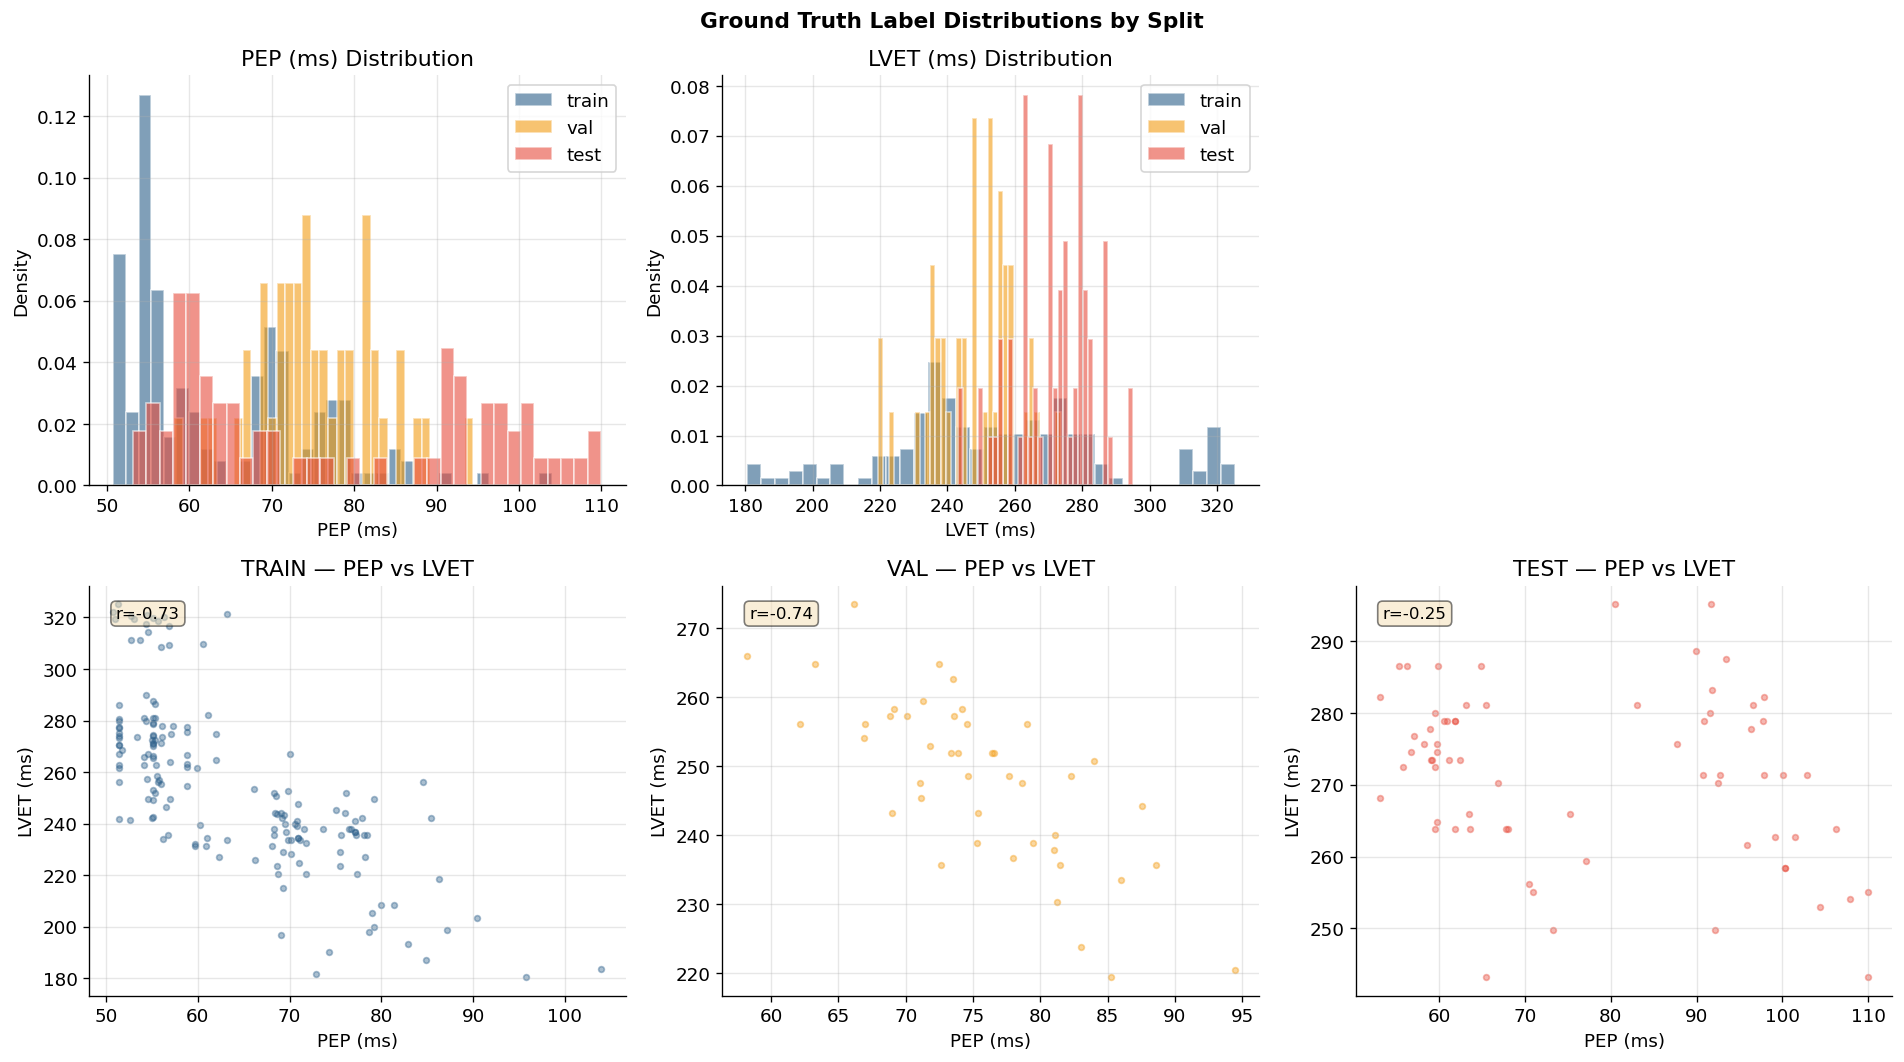

In [12]:
# Label distribution across splits
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Ground Truth Label Distributions by Split', fontsize=13, fontweight='bold')

split_colors = {'train': '#2C5F8A', 'val': '#F39C12', 'test': '#E74C3C'}
splits_loaded = {}
for split in ['train', 'val', 'test']:
    try:
        splits_loaded[split] = load_split(FINAL_DATASET_DIR, split)
    except FileNotFoundError:
        pass

for col, (ykey, ylabel) in enumerate([('y_pep', 'PEP (ms)'), ('y_lvet', 'LVET (ms)')]):
    ax = axes[0, col*3//2] if col < 2 else axes[0, 2]
    for split, color in split_colors.items():
        if split in splits_loaded:
            vals = splits_loaded[split][ykey]
            axes[0, col].hist(vals, bins=35, alpha=0.6, color=color, label=split, edgecolor='white', density=True)
    axes[0, col].set_xlabel(ylabel)
    axes[0, col].set_ylabel('Density')
    axes[0, col].set_title(f'{ylabel} Distribution')
    axes[0, col].legend()

# PEP vs LVET scatter per split
for col, split in enumerate(['train', 'val', 'test']):
    ax = axes[1, col]
    if split in splits_loaded:
        ds = splits_loaded[split]
        sample_n = min(500, len(ds['y_pep']))
        idx = np.random.choice(len(ds['y_pep']), sample_n, replace=False)
        ax.scatter(ds['y_pep'][idx], ds['y_lvet'][idx], alpha=0.4, s=12, 
                   color=split_colors[split])
        ax.set_xlabel('PEP (ms)')
        ax.set_ylabel('LVET (ms)')
        ax.set_title(f'{split.upper()} — PEP vs LVET')
        # Compute correlation
        r = np.corrcoef(ds['y_pep'], ds['y_lvet'])[0,1]
        ax.text(0.05, 0.95, f'r={r:.2f}', transform=ax.transAxes,
                fontsize=10, va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Remove unused subplot
axes[0, 2].set_visible(False)
plt.tight_layout()
plt.show()

Feature matrix shape: (166, 30)


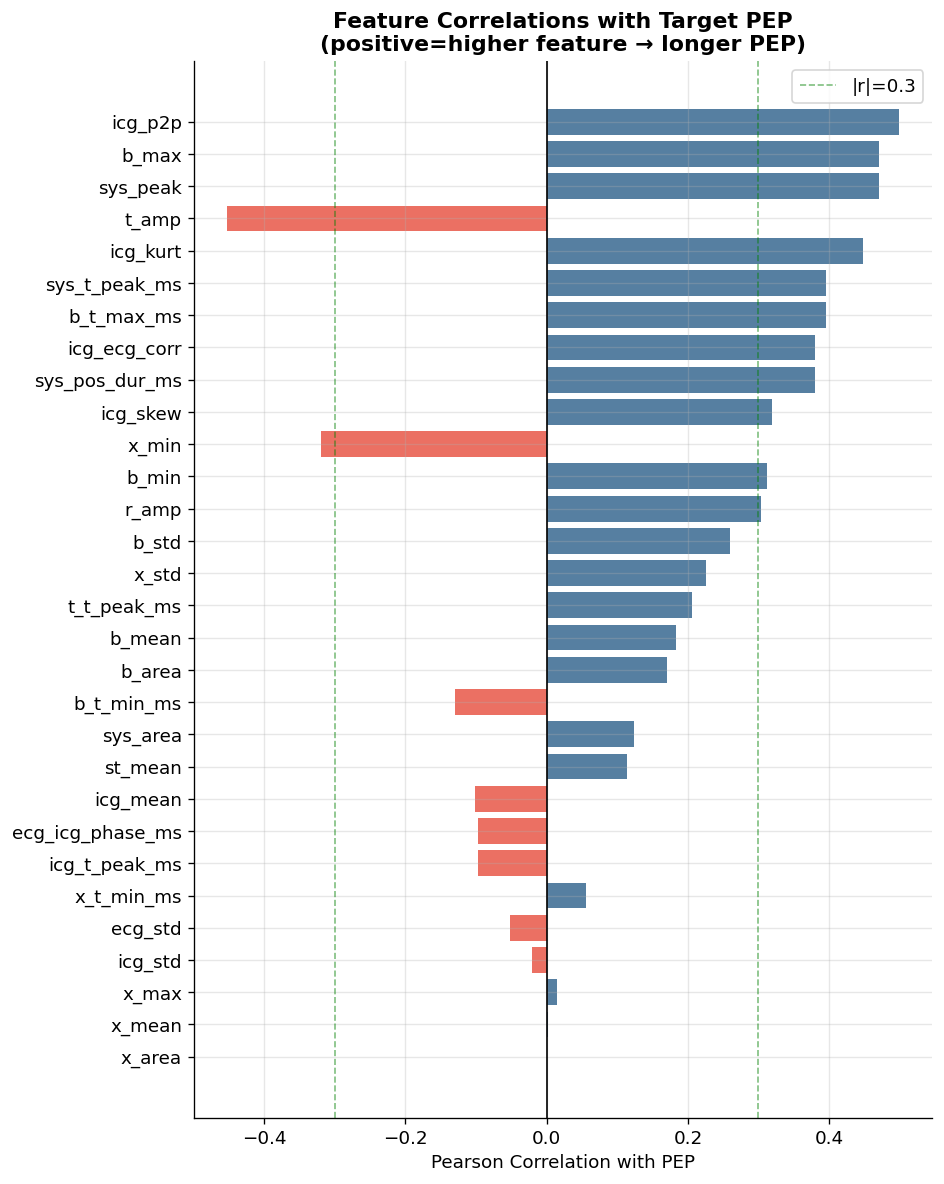

In [13]:
# Feature matrix inspection
if 'train' in splits_loaded:
    X_feat = splits_loaded['train']['X_feat']
    feat_names_path = Path(FINAL_DATASET_DIR) / 'train' / 'feature_names.json'
    with open(feat_names_path) as f:
        feat_names = json.load(f)
    
    print(f'Feature matrix shape: {X_feat.shape}')
    
    # Feature importance proxy: correlation with PEP
    y_pep = splits_loaded['train']['y_pep']
    corrs = [np.corrcoef(X_feat[:, i], y_pep)[0,1] for i in range(X_feat.shape[1])]
    corr_df = pd.DataFrame({'feature': feat_names, 'corr_with_pep': corrs})
    corr_df['abs_corr'] = corr_df['corr_with_pep'].abs()
    corr_df = corr_df.sort_values('abs_corr', ascending=True)
    
    fig, ax = plt.subplots(figsize=(8, 10))
    colors = ['#2C5F8A' if c > 0 else '#E74C3C' for c in corr_df['corr_with_pep']]
    ax.barh(corr_df['feature'], corr_df['corr_with_pep'], color=colors, alpha=0.8)
    ax.axvline(0, color='black', linewidth=1)
    ax.axvline(0.3, color='green', linewidth=1, linestyle='--', alpha=0.5, label='|r|=0.3')
    ax.axvline(-0.3, color='green', linewidth=1, linestyle='--', alpha=0.5)
    ax.set_xlabel('Pearson Correlation with PEP')
    ax.set_title('Feature Correlations with Target PEP\n(positive=higher feature → longer PEP)', fontweight='bold')
    ax.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# Print final loading code for models
print('=' * 60)
print('STEP 3 COMPLETE — FINAL DATASET READY')
print('=' * 60)

total = sum(s.get('n_valid', 0) for s in split_summaries.values())
for split, s in split_summaries.items():
    print(f'  {split.upper():10s}: {s.get("n_valid",0):5,d} beats | '
          f'PEP: {s.get("pep_mean",0):.0f}±{s.get("pep_std",0):.0f}ms | '
          f'LVET: {s.get("lvet_mean",0):.0f}±{s.get("lvet_std",0):.0f}ms')
print(f'  {"TOTAL":10s}: {total:5,d} beats')

print('\n--- HOW TO LOAD IN YOUR MODELS ---')
print('''
import numpy as np
from pathlib import Path

def load_split(data_dir, split='train'):
    d = Path(data_dir) / split
    return {
        # Model inputs
        'X_icg':   np.load(d / 'X_icg.npy'),     # (N, 200) ICG only
        'X_ecg':   np.load(d / 'X_ecg.npy'),     # (N, 200) ECG only
        'X_multi': np.load(d / 'X_multi.npy'),   # (N, 2, 200) ICG+ECG
        'X_feat':  np.load(d / 'X_features.npy'),# (N, 30) hand-crafted
        # Targets
        'y_pep':   np.load(d / 'y_pep.npy'),     # (N,) ms
        'y_lvet':  np.load(d / 'y_lvet.npy'),    # (N,) ms
        # Metadata
        'biases':  np.load(d / 'biases.npy'),    # (N,4) ICG bias per beat
        'cp_idx':  np.load(d / 'cp_indices.npy'),# (N,3) R/B/X positions
    }

train = load_split('./output/final_dataset', 'train')
val   = load_split('./output/final_dataset', 'val')
# test = load_split('./output/final_dataset', 'test')  # ONLY at final eval!
''')
print('NEXT: Run Notebook 04 — EDA & Bias Analysis (RQ1)')

STEP 3 COMPLETE — FINAL DATASET READY
  TRAIN     :   166 beats | PEP: 64±11ms | LVET: 255±32ms
  VAL       :    44 beats | PEP: 75±7ms | LVET: 248±12ms
  TEST      :    69 beats | PEP: 77±18ms | LVET: 271±12ms
  TOTAL     :   279 beats

--- HOW TO LOAD IN YOUR MODELS ---

import numpy as np
from pathlib import Path

def load_split(data_dir, split='train'):
    d = Path(data_dir) / split
    return {
        # Model inputs
        'X_icg':   np.load(d / 'X_icg.npy'),     # (N, 200) ICG only
        'X_ecg':   np.load(d / 'X_ecg.npy'),     # (N, 200) ECG only
        'X_multi': np.load(d / 'X_multi.npy'),   # (N, 2, 200) ICG+ECG
        'X_feat':  np.load(d / 'X_features.npy'),# (N, 30) hand-crafted
        # Targets
        'y_pep':   np.load(d / 'y_pep.npy'),     # (N,) ms
        'y_lvet':  np.load(d / 'y_lvet.npy'),    # (N,) ms
        # Metadata
        'biases':  np.load(d / 'biases.npy'),    # (N,4) ICG bias per beat
        'cp_idx':  np.load(d / 'cp_indices.npy'),# (N,3) R/B/X

In [15]:
recs = all_data['CHC01']['records']
bias_s = np.concatenate([r['biases'] for r in recs])
x_bias, lvet_bias = bias_s[:,1], bias_s[:,3]
vx, vl = x_bias[~np.isnan(x_bias)], lvet_bias[~np.isnan(lvet_bias)]
print(f'X-bias:    matched {len(vx)}/{len(x_bias)} beats | mean={vx.mean():.1f}  median={np.median(vx):.1f}  range=[{vx.min():.1f}, {vx.max():.1f}]')
print(f'LVET-bias: matched {len(vl)}/{len(lvet_bias)} beats | mean={vl.mean():.1f}  median={np.median(vl):.1f}  range=[{vl.min():.1f}, {vl.max():.1f}]')

X-bias:    matched 22/107 beats | mean=38.3  median=30.9  range=[-36.1, 312.8]
LVET-bias: matched 16/107 beats | mean=131.2  median=46.3  range=[4.4, 273.6]
